In [25]:
import pandas as pd
import numpy as np
import cv2
import os
from pathlib import Path
from PIL import Image

IMG_SIZE = 224
IMG_EXT = ('.png', '.jpeg', '.jpg', '.bmp')
SEED = 42

BASE_DIRE = Path(r"C:\BrainScan_V2")
DATA_DIR = BASE_DIRE / 'data' / 'raw'
df = pd.DataFrame()
print(np.__version__)
DATA_DIR.exists()

2.5.3


True

## 1. Chargement et prétraitement du dataset

### 1.1 Exploration des classes

In [31]:
classes = sorted(c for c in DATA_DIR.iterdir() if c.is_dir())
classes
for c in classes:
    count = len(list(c.iterdir()))
    print(f"{c.name}: {count}")

# for class_path in classes:
#     print(class_path)


glioma: 1621
meningioma: 1645
notumor: 2000
pituitary: 1757


### 1.2 Contrôle qualité



In [32]:
valid, invalid = [], []

for class_Path in classes:

    for file in class_Path.iterdir():
        if file.suffix.lower() not in IMG_EXT :
            invalid.append((str(file), "bad extension"))
            continue
        try:
            img = cv2.imread(file)
            valid.append((str(file), class_Path.name))
        except Exception as e:
            invalid.append((str(file), f"corrupted: {e}"))

df = pd.DataFrame(valid, columns=['path', 'label'])
print(f"Valid images:   {len(df)}")
print(f"Invalid images: {len(invalid)}")         
df

Valid images:   7023
Invalid images: 0


,path,label
0,C:\BrainScan_V2\data\raw\glioma\Te-glTr_0000.jpg,glioma
1,C:\BrainScan_V2\data\raw\glioma\Te-glTr_0001.jpg,glioma
2,C:\BrainScan_V2\data\raw\glioma\Te-glTr_0002.jpg,glioma
3,C:\BrainScan_V2\data\raw\glioma\Te-glTr_0003.jpg,glioma
4,C:\BrainScan_V2\data\raw\glioma\Te-glTr_0004.jpg,glioma
...,...,...
7018,C:\BrainScan_V2\data\raw\pituitary\Tr-pi_1452.jpg,pituitary
7019,C:\BrainScan_V2\data\raw\pituitary\Tr-pi_1453.jpg,pituitary
7020,C:\BrainScan_V2\data\raw\pituitary\Tr-pi_1454.jpg,pituitary
7021,C:\BrainScan_V2\data\raw\pituitary\Tr-pi_1455.jpg,pituitary


Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
label
notumor       2000
pituitary     1757
meningioma    1645
glioma        1621
Name: count, dtype: int64


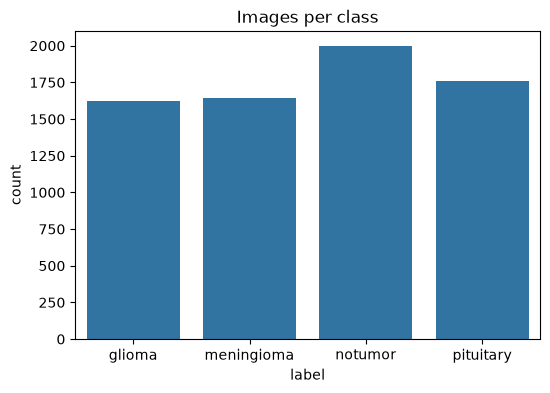

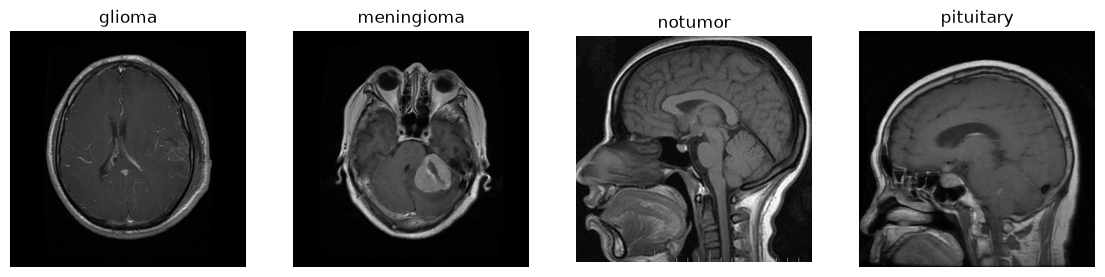

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. classes = folder names
classes = sorted(df["label"].unique())
print("Classes:", classes)
print(df["label"].value_counts())

# 2. countplot
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="label", order=classes)
plt.title("Images per class")
plt.show()

# 3. one sample per class
fig, axes = plt.subplots(1, len(classes), figsize=(14, 8))
for ax, cls in zip(axes, classes):
    sample_path = df[df['label'] == cls].sample(1)['path'].values[0]
    ax.imshow(Image.open(sample_path), cmap='gray')
    ax.set_title(cls)
    ax.axis("off")
    

plt.show()

Train: 4916
valid: 1053
test: 1054


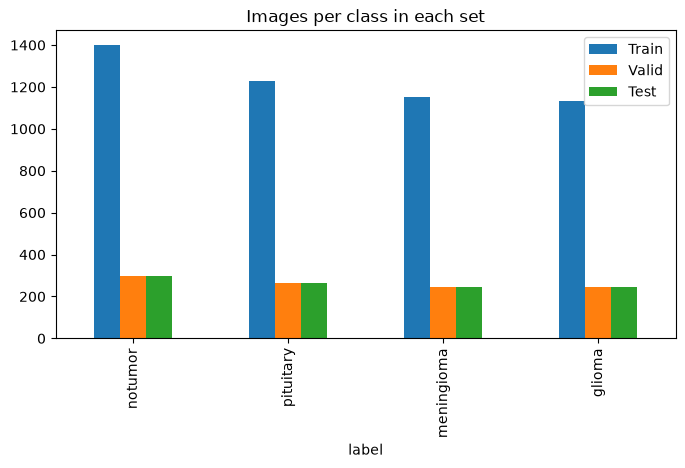

In [64]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df, test_size=0.3, stratify=df['label'], random_state=SEED
)

valid_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['label'], random_state=SEED
)
print('Train:', len(train_df))
print('valid:', len(valid_df))
print('test:', len(test_df))

counts = pd.DataFrame({
    'Train':train_df['label'].value_counts(),
    'Valid':valid_df['label'].value_counts(),
    'Test':test_df['label'].value_counts()
})
counts

counts.plot(kind='bar', figsize=(8, 4), title="Images per class in each set")
plt.show()